# H2S-NN Node Embedding Separability During Training

This Colab notebook runs `scripts/visualize_embedding_separability_training.py` on PyTorch Geometric's four-class `FakeHeteroDataset`. It records target-node embeddings at epochs 0, 5, 10, ... and renders a shared-coordinate PCA trajectory by default.

## 1. Mount Google Drive and enter the repository

In [2]:
from pathlib import Path
import os
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/H2S-NN_test')
else:
    PROJECT_DIR = Path.cwd()

if not PROJECT_DIR.exists():
    raise FileNotFoundError(f'Repository not found: {PROJECT_DIR}')
os.chdir(PROJECT_DIR)
print('Working directory:', PROJECT_DIR)
print('Python executable:', sys.executable)

Mounted at /content/drive
Working directory: /content/drive/MyDrive/H2S-NN_test
Python executable: /usr/bin/python3


## 2. Install Colab dependencies

The PyG wheel URL is derived from the active Colab PyTorch version. The optional `umap-learn` package is installed only so the projection method can be changed later.

In [3]:
import subprocess
import sys
import torch

torch_version = torch.__version__.split('+')[0]
cuda_tag = 'cpu' if torch.version.cuda is None else 'cu' + torch.version.cuda.replace('.', '')
wheel_url = f'https://data.pyg.org/whl/torch-{torch_version}+{cuda_tag}.html'
print('torch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('PyG wheel URL:', wheel_url)

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn', 'matplotlib', 'umap-learn', 'pyyaml'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch-geometric', 'torch-scatter', 'torch-sparse', '-f', wheel_url])

torch: 2.11.0+cu128
CUDA available: True
PyG wheel URL: https://data.pyg.org/whl/torch-2.11.0+cu128.html


0

## 3. Choose the run settings

In [22]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 42
EPOCHS = 50
SNAPSHOT_EVERY = 10
HIDDEN_DIM = 16
DIFFUSION_STEPS = 3
PROJECTION = 'all'       # 'pca', 'tsne', or 'umap'
USE_ORTHOGONAL = True  # True follows the full FastHPP configuration but uses more memory
OUTPUT = Path('figures/fakehetero_embedding_separability.png')

print({
    'device': DEVICE,
    'epochs': EPOCHS,
    'snapshot_every': SNAPSHOT_EVERY,
    'projection': PROJECTION,
    'output': str(OUTPUT),
})

{'device': 'cuda', 'epochs': 50, 'snapshot_every': 10, 'projection': 'all', 'output': 'figures/fakehetero_embedding_separability.png'}


## 4. Check the script interface

In [19]:
import subprocess
import sys

subprocess.run([sys.executable, 'scripts/visualize_embedding_separability_training.py', '--help'], check=True)

CompletedProcess(args=['/usr/bin/python3', 'scripts/visualize_embedding_separability_training.py', '--help'], returncode=0)

## 5. Train and create the visualization

The script also saves a compressed trajectory (`.npz`) and the per-snapshot raw-space silhouette scores (`.json`) next to the figure.

In [23]:
command = [
    sys.executable,
    '-u',
    'scripts/visualize_embedding_separability_training.py',
    '--output', str(OUTPUT),
    '--method', PROJECTION,
    '--device', DEVICE,
    '--epochs', str(EPOCHS),
    '--snapshot-every', str(SNAPSHOT_EVERY),
    '--hidden-dim', str(HIDDEN_DIM),
    '--diffusion-steps', str(DIFFUSION_STEPS),
    '--seed', str(SEED),
]
if USE_ORTHOGONAL:
    command.append('--use-orthogonal')

print('Running:', ' '.join(command))
try:
    result = subprocess.run(command, capture_output=True, text=True, check=True)
    print("Standard output:")
    print(result.stdout)
    print("Standard error:")
    print(result.stderr)
except subprocess.CalledProcessError as e:
    print(f"Command failed with exit code {e.returncode}")
    print("Standard output:")
    print(e.stdout)
    print("Standard error:")
    print(e.stderr)
    raise # Re-raise the exception after printing details

Running: /usr/bin/python3 -u scripts/visualize_embedding_separability_training.py --output figures/fakehetero_embedding_separability.png --method all --device cuda --epochs 50 --snapshot-every 10 --hidden-dim 16 --diffusion-steps 3 --seed 42 --use-orthogonal
Standard output:
FakeHeteroDataset: nodes=985 target_nodes=307 edges=10019 face_instances=1927 target_type=v0 classes=4 class_counts=[79, 71, 77, 80] device=cuda
epoch=5/50 loss=1.3132 snapshot_epoch=0 snapshot_silhouette=-0.0173
epoch=10/50 loss=1.2371 snapshot_epoch=10 snapshot_silhouette=-0.0056
epoch=15/50 loss=1.1383 snapshot_epoch=10 snapshot_silhouette=-0.0056
epoch=20/50 loss=1.0148 snapshot_epoch=20 snapshot_silhouette=0.0313
epoch=25/50 loss=0.8990 snapshot_epoch=20 snapshot_silhouette=0.0313
epoch=30/50 loss=0.7502 snapshot_epoch=30 snapshot_silhouette=0.0910
epoch=35/50 loss=0.6028 snapshot_epoch=30 snapshot_silhouette=0.0910
epoch=40/50 loss=0.4860 snapshot_epoch=40 snapshot_silhouette=0.1412
epoch=45/50 loss=0.3834 sn

## 6. Display the result and inspect the metrics

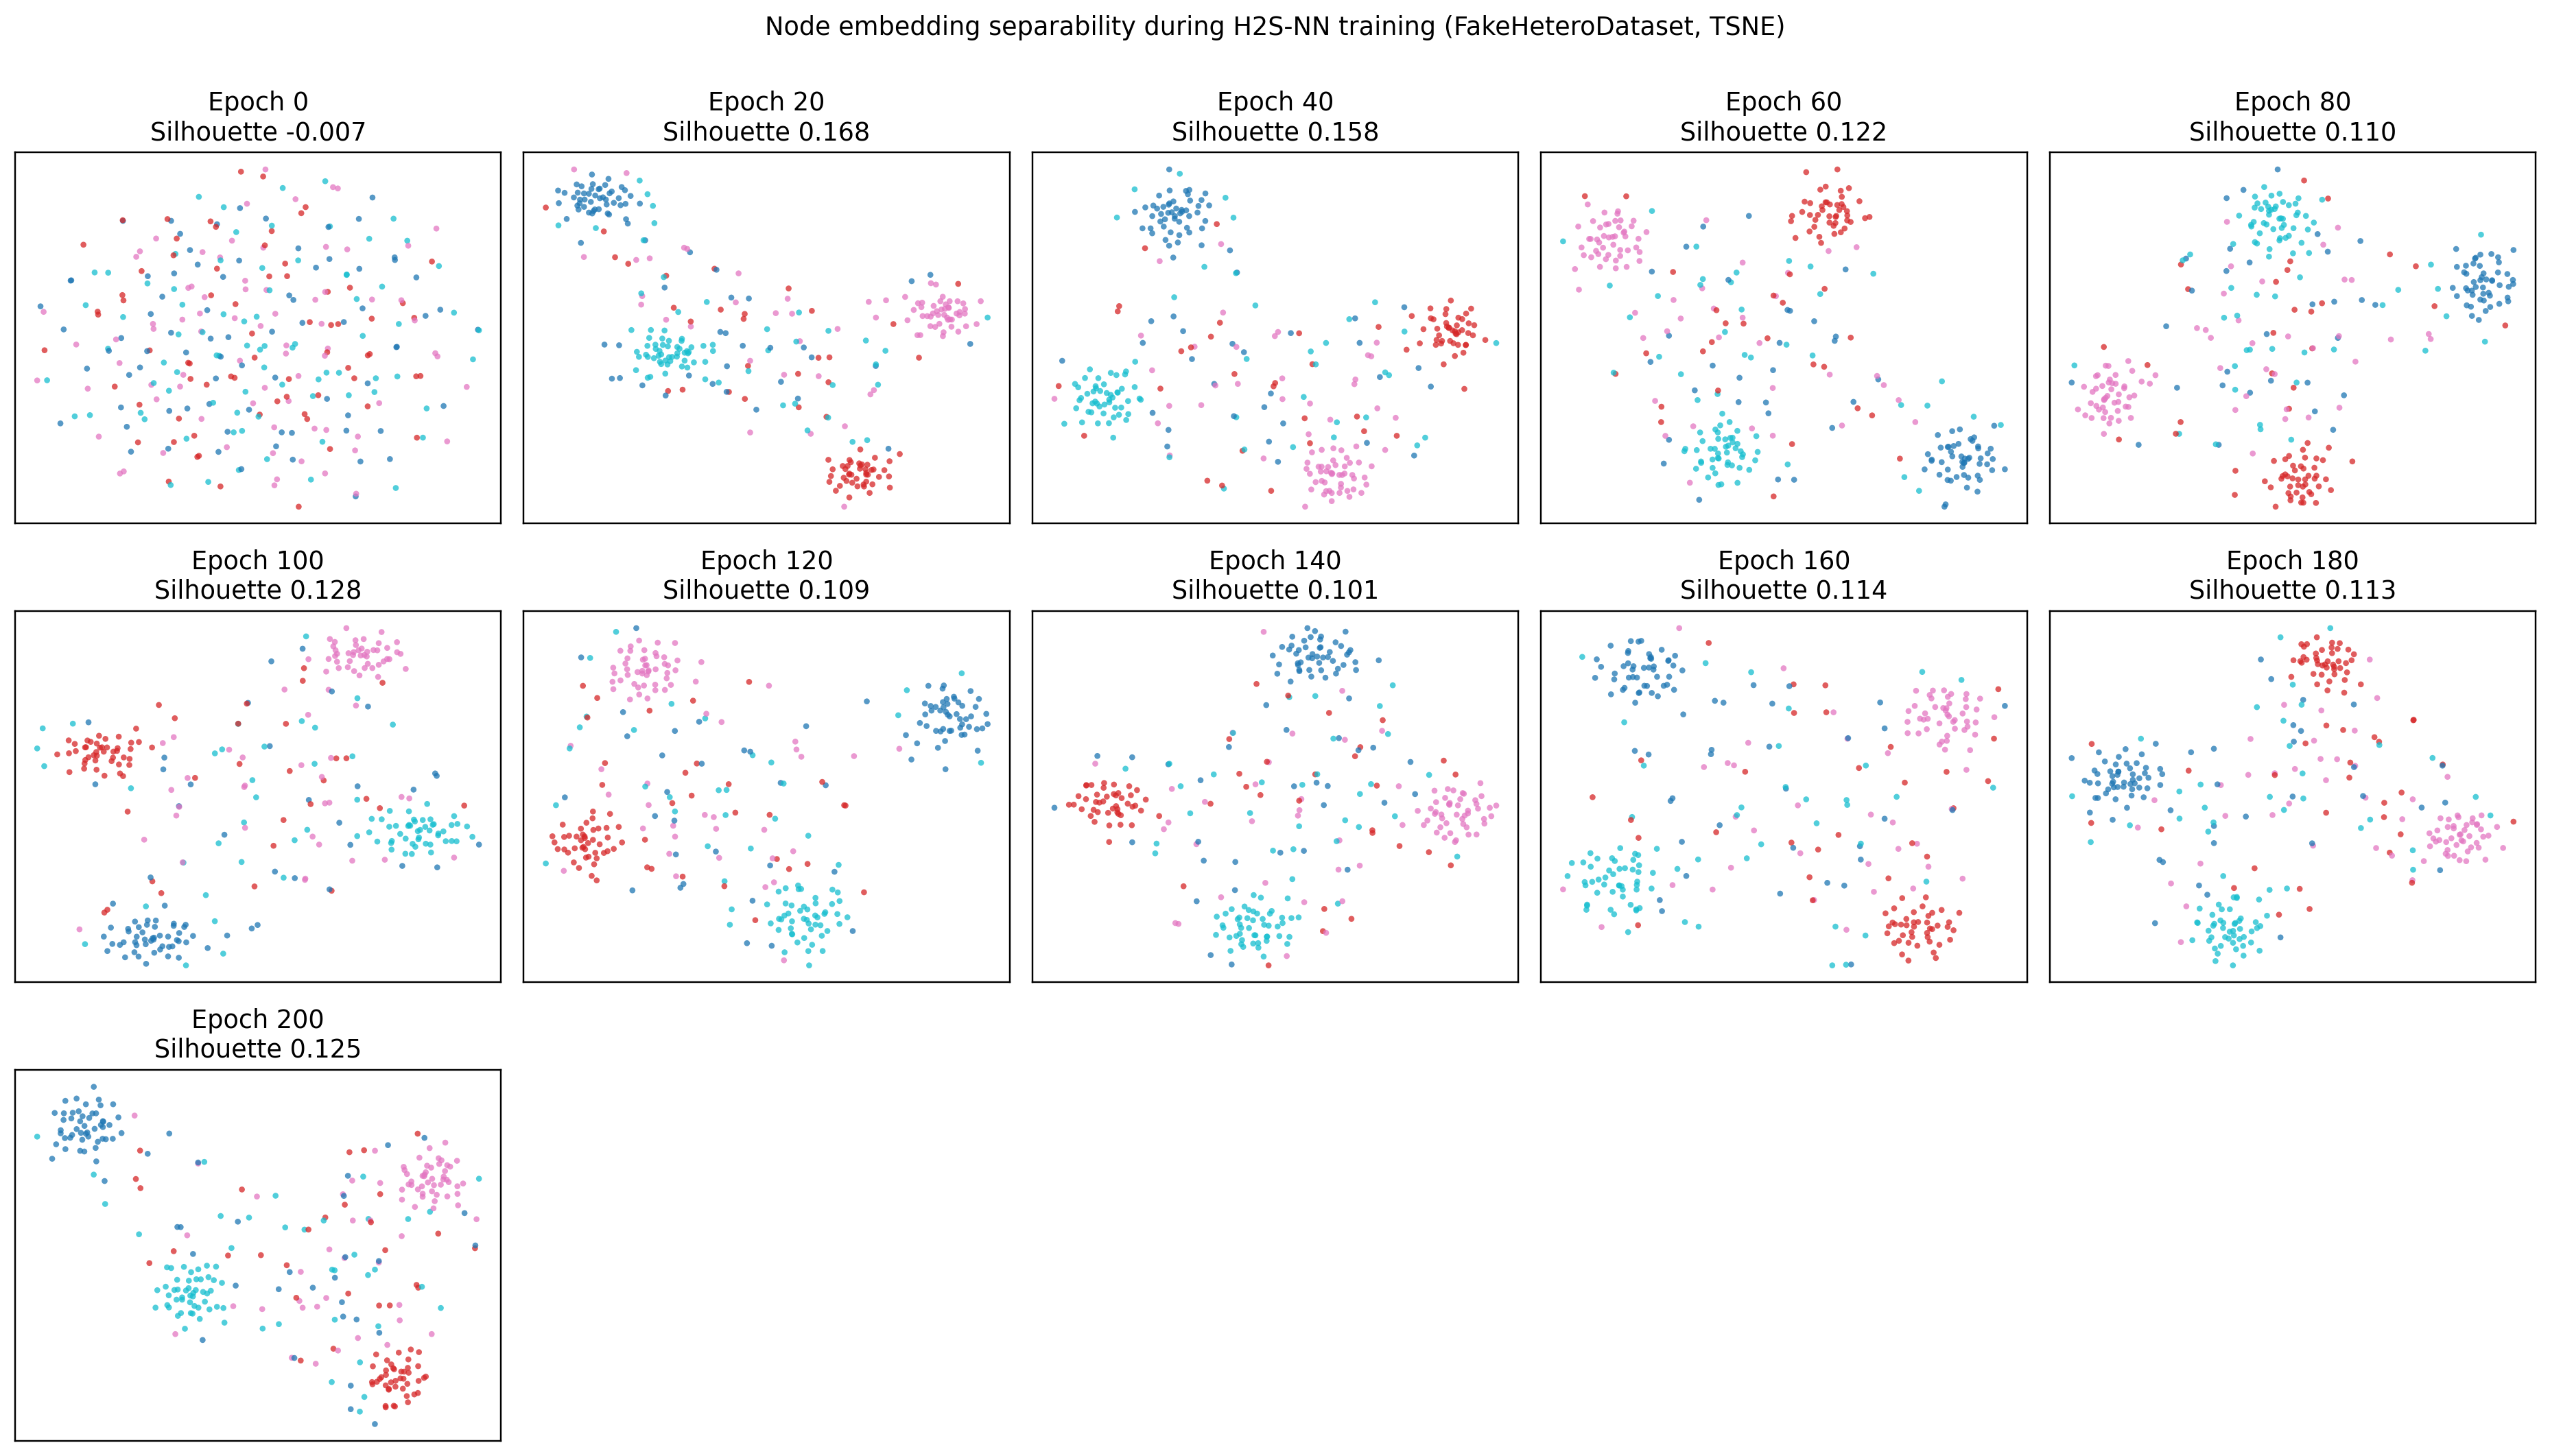

epoch=  0
epoch= 10
epoch= 20
epoch= 30
epoch= 40
epoch= 50


In [27]:
from IPython.display import Image, display
import json

display(Image(filename=str(OUTPUT)))
metrics = json.loads(OUTPUT.with_suffix('.json').read_text(encoding='utf-8'))
for epoch, score in zip(metrics['epochs'], metrics['silhouette']):
    print(f'epoch={epoch:>3}  silhouette={score:.4f}')